# Eksplorasi Data Deret Waktu (EDA), Uji Stasioneritas, & Model Acuan (Baseline) - R.Syailindra Alfarraiel - 24083010030

## Setup library dan Import Data

In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Konfigurasi gaya visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True

# Path Data dan Figures
DATA_DIR = "../data"
FIGURES_DIR = os.path.join(DATA_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

CSV_INPUT_PATH = os.path.join(DATA_DIR, "seri_harian.csv")

# Load data
df = pd.read_csv(CSV_INPUT_PATH, parse_dates=['tanggal'], index_col='tanggal')
komoditas_cols = ['cabe_rawit', 'bawang_merah', 'beras_premium']

print(f"Data berhasil dimuat. Periode: {df.index.min().strftime('%Y-%m-%d')} s/d {df.index.max().strftime('%Y-%m-%d')}")
print(f"Total baris: {len(df)} hari | Komoditas: {komoditas_cols}")
df

Data berhasil dimuat. Periode: 2023-01-01 s/d 2026-02-28
Total baris: 1155 hari | Komoditas: ['cabe_rawit', 'bawang_merah', 'beras_premium']


,beras_premium,cabe_rawit,bawang_merah
tanggal,,,
2023-01-01,12471.42857,47857.14286,31857.14286
2023-01-02,12471.42857,61428.57143,32571.42857
2023-01-03,12471.42857,64285.71429,32571.42857
2023-01-04,12471.42857,65000.00000,32714.28571
2023-01-05,12471.42857,57857.14286,32571.42857
...,...,...,...
2026-02-24,15814.28571,75000.00000,36714.28571
2026-02-25,15814.28571,78571.42857,36285.71429
2026-02-26,15814.28571,80000.00000,36285.71429


## Statistika deskriptif dan bukti 3 komoditas yang volatile

In [6]:
summary_stats = []

for col in komoditas_cols:
    mean_val = df[col].mean()
    std_val = df[col].std()
    min_val = df[col].min()
    max_val = df[col].max()
    cv_val = std_val / mean_val  # Coefficient of Variation
    
    # Kategori rezim
    if cv_val > 0.3:
        rezim = "Tinggi"
    elif cv_val > 0.1:
        rezim = "Sedang"
    else:
        rezim = "Rendah"
        
    summary_stats.append({
        'Komoditas': col,
        'Mean (Rp)': mean_val,
        'Std Dev (Rp)': std_val,
        'Min (Rp)': min_val,
        'Max (Rp)': max_val,
        'CV': cv_val,
        'Rezim Volatilitas': rezim
    })

df_summary = pd.DataFrame(summary_stats).set_index('Komoditas')
display(df_summary)

# Simpan tabel ke data/
summary_xlsx = os.path.join(DATA_DIR, "statistika_deskriptif.xlsx")
summary_csv = os.path.join(DATA_DIR, "statistika_deskriptif.csv")
df_summary.to_excel(summary_xlsx)
df_summary.to_csv(summary_csv)
print(f"[Tersimpan] Tabel ringkasan statistik: {summary_xlsx}")

,Mean (Rp),Std Dev (Rp),Min (Rp),Max (Rp),CV,Rezim Volatilitas
Komoditas,,,,,,
cabe_rawit,54968.104514,9202.638898,29000.000000,105000.000000,0.167418,Sedang
bawang_merah,32443.528581,4177.174809,23285.714286,41500.000000,0.128752,Sedang
beras_premium,14916.747062,1051.923525,12471.428570,16171.428571,0.070520,Rendah


[Tersimpan] Tabel ringkasan statistik: ../data/statistika_deskriptif.xlsx


## Visualisasi pergerakan

[Tersimpan] Gambar tren harga: ../data/figures/01_tren_harga_historis.png


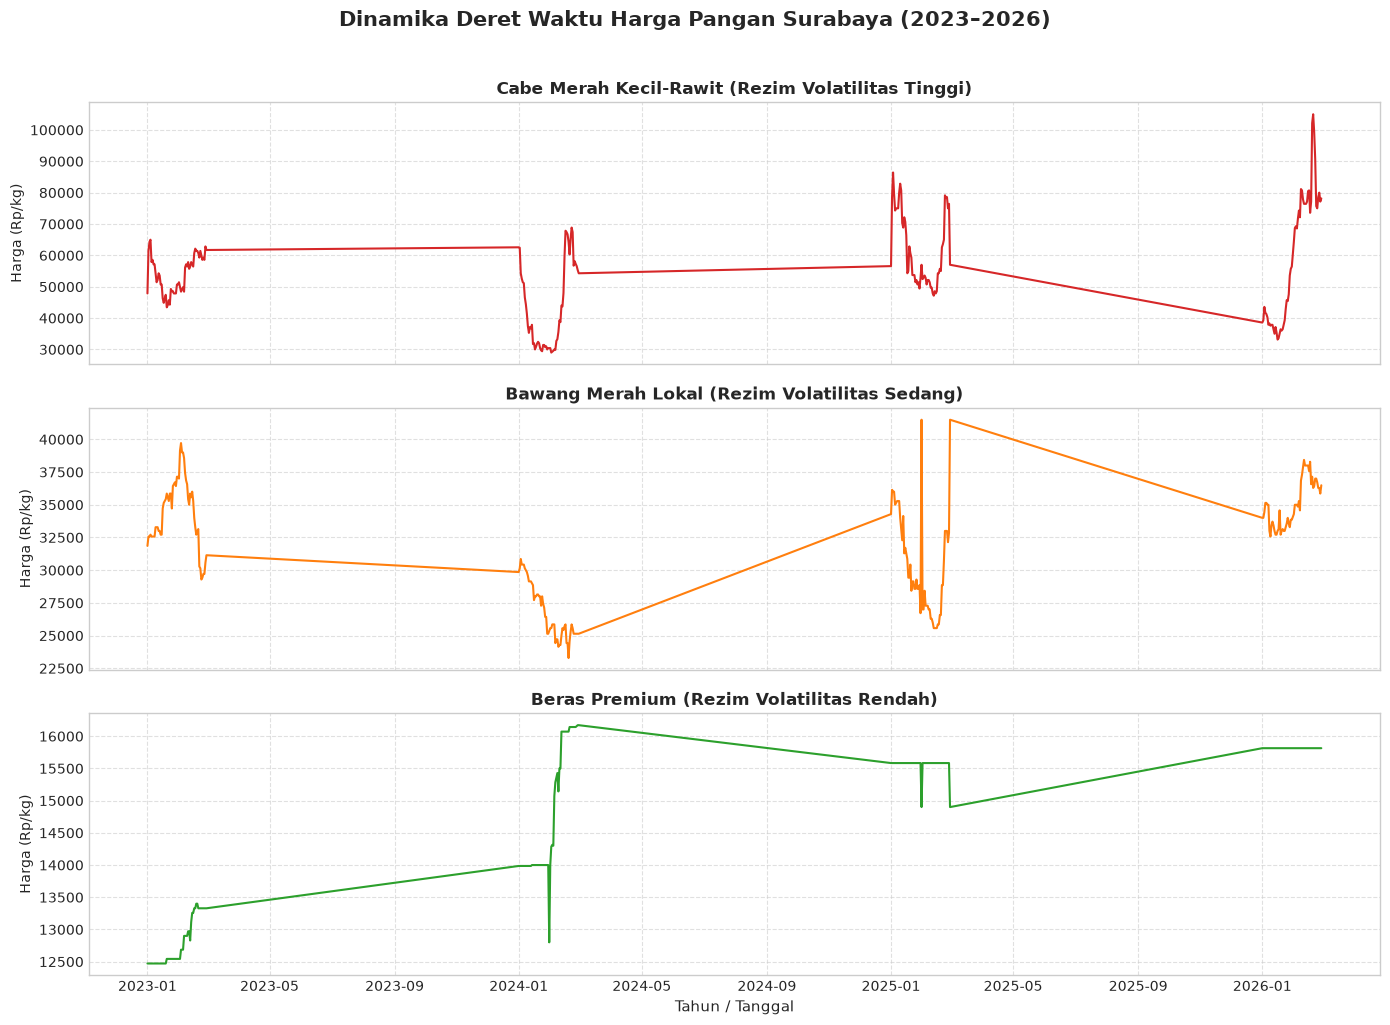

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

colors = {'cabe_rawit': '#d62728', 'bawang_merah': '#ff7f0e', 'beras_premium': '#2ca02c'}
titles = {
    'cabe_rawit': 'Cabe Merah Kecil-Rawit (Rezim Volatilitas Tinggi)',
    'bawang_merah': 'Bawang Merah Lokal (Rezim Volatilitas Sedang)',
    'beras_premium': 'Beras Premium (Rezim Volatilitas Rendah)'
}

for i, col in enumerate(komoditas_cols):
    axes[i].plot(df.index, df[col], label=col, color=colors[col], linewidth=1.5)
    axes[i].set_title(titles[col], fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Harga (Rp/kg)', fontsize=10)
    axes[i].grid(True, linestyle='--', alpha=0.6)

axes[2].set_xlabel('Tahun / Tanggal', fontsize=11)
plt.suptitle('Dinamika Deret Waktu Harga Pangan Surabaya (2023–2026)', fontsize=15, fontweight='bold', y=1.02)

fig_path = os.path.join(FIGURES_DIR, "01_tren_harga_historis.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"[Tersimpan] Gambar tren harga: {fig_path}")
plt.show()

## Visualisasi Pola Distribusi & Deteksi Outlier (Boxplot Tahunan)

/tmp/ipykernel_24946/428140356.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='tahun', y=col, data=df_plot, ax=axes[i], palette="Blues")
/tmp/ipykernel_24946/428140356.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='tahun', y=col, data=df_plot, ax=axes[i], palette="Blues")
/tmp/ipykernel_24946/428140356.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='tahun', y=col, data=df_plot, ax=axes[i], palette="Blues")


[Tersimpan] Gambar boxplot tahunan: ../data/figures/02_boxplot_tahunan.png


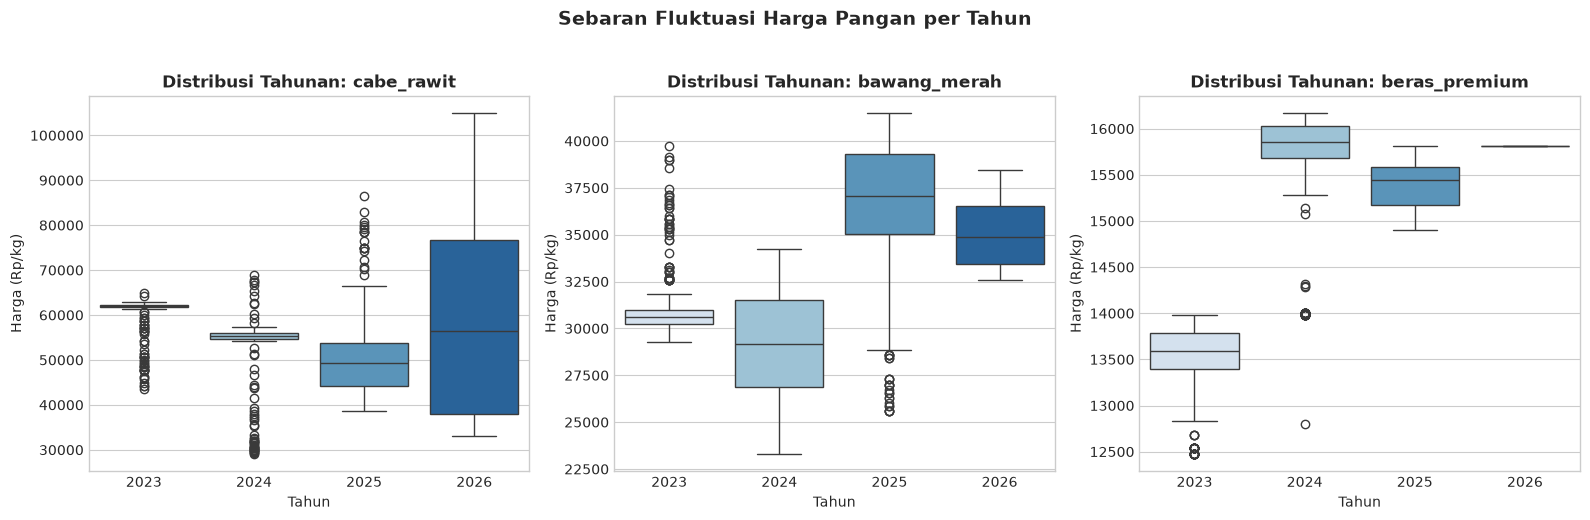

In [9]:
df_plot = df.copy()
df_plot['tahun'] = df_plot.index.year

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(komoditas_cols):
    sns.boxplot(x='tahun', y=col, data=df_plot, ax=axes[i], palette="Blues")
    axes[i].set_title(f'Distribusi Tahunan: {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Tahun', fontsize=10)
    axes[i].set_ylabel('Harga (Rp/kg)', fontsize=10)

plt.suptitle('Sebaran Fluktuasi Harga Pangan per Tahun', fontsize=14, fontweight='bold', y=1.03)

fig_path = os.path.join(FIGURES_DIR, "02_boxplot_tahunan.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"[Tersimpan] Gambar boxplot tahunan: {fig_path}")
plt.show()

In [10]:
def check_stationarity(series):
    # 1. ADF Test (H0: Data memiliki unit root / tidak stasioner)
    adf_res = adfuller(series.dropna())
    adf_stat, adf_p = adf_res[0], adf_res[1]
    adf_stasioner = "Ya" if adf_p < 0.05 else "Tidak"
    
    # 2. KPSS Test (H0: Data stasioner)
    kpss_res = kpss(series.dropna(), regression='c', nlags="auto")
    kpss_stat, kpss_p = kpss_res[0], kpss_res[1]
    kpss_stasioner = "Ya" if kpss_p >= 0.05 else "Tidak"
    
    return {
        'ADF Stat': adf_stat,
        'ADF p-value': adf_p,
        'ADF Stasioner': adf_stasioner,
        'KPSS Stat': kpss_stat,
        'KPSS p-value': kpss_p,
        'KPSS Stasioner': kpss_stasioner
    }

stationarity_results = []

for col in komoditas_cols:
    # Level asli
    lvl_res = check_stationarity(df[col])
    stationarity_results.append({
        'Komoditas': col,
        'Bentuk': 'Level Asli',
        **lvl_res
    })
    
    # First Differencing (d=1)
    diff_res = check_stationarity(df[col].diff().dropna())
    stationarity_results.append({
        'Komoditas': col,
        'Bentuk': 'First Difference (d=1)',
        **diff_res
    })

df_stationarity = pd.DataFrame(stationarity_results)
display(df_stationarity)

# Simpan tabel ke data/
stationarity_xlsx = os.path.join(DATA_DIR, "uji_stasioneritas.xlsx")
stationarity_csv = os.path.join(DATA_DIR, "uji_stasioneritas.csv")
df_stationarity.to_excel(stationarity_xlsx, index=False)
df_stationarity.to_csv(stationarity_csv, index=False)
print(f"[Tersimpan] Tabel uji stasioneritas: {stationarity_xlsx}")

/tmp/ipykernel_24946/1101132281.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_res = adfuller(series.dropna())
/tmp/ipykernel_24946/1101132281.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_res = kpss(series.dropna(), regression='c', nlags="auto")
/tmp/ipykernel_24946/1101132281.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always retu

,Komoditas,Bentuk,ADF Stat,ADF p-value,ADF Stasioner,KPSS Stat,KPSS p-value,KPSS Stasioner
0,cabe_rawit,Level Asli,-3.733379,3.667413e-03,Ya,1.125525,0.01,Tidak
1,cabe_rawit,First Difference (d=1),-8.569440,8.274109e-14,Ya,0.059987,0.10,Ya
2,bawang_merah,Level Asli,-1.822925,3.691411e-01,Tidak,2.484425,0.01,Tidak
3,bawang_merah,First Difference (d=1),-7.224484,2.070128e-10,Ya,0.047116,0.10,Ya
4,beras_premium,Level Asli,-2.265027,1.834957e-01,Tidak,3.537747,0.01,Tidak
5,beras_premium,First Difference (d=1),-8.263296,5.015689e-13,Ya,0.245172,0.10,Ya


[Tersimpan] Tabel uji stasioneritas: ../data/uji_stasioneritas.xlsx


In [11]:
# Train-Test Split kronologis sederhana untuk evaluasi baseline awal (Fold 1: Test 2025-01 s/d 2025-06)
split_date_train_end = '2024-12-31'
split_date_test_end = '2025-06-30'

baseline_records = []

for col in komoditas_cols:
    train_series = df.loc[:split_date_train_end, col]
    test_series = df.loc['2025-01-01':split_date_test_end, col]
    
    # 1. Naive: y_hat(t) = y(t-1)
    # Pada data test, prediksi hari t adalah nilai aktual t-1
    full_series = df.loc[:split_date_test_end, col]
    naive_pred = full_series.shift(1).loc['2025-01-01':split_date_test_end]
    
    # 2. Seasonal Naive: y_hat(t) = y(t-7)
    snaive_pred = full_series.shift(7).loc['2025-01-01':split_date_test_end]
    
    # Evaluasi metrik
    mae_naive = mean_absolute_error(test_series, naive_pred)
    rmse_naive = np.sqrt(mean_squared_error(test_series, naive_pred))
    
    mae_snaive = mean_absolute_error(test_series, snaive_pred)
    rmse_snaive = np.sqrt(mean_squared_error(test_series, snaive_pred))
    
    baseline_records.append({
        'Komoditas': col,
        'Model Baseline': 'Naive (Lag 1)',
        'MAE (Rp)': mae_naive,
        'RMSE (Rp)': rmse_naive
    })
    baseline_records.append({
        'Komoditas': col,
        'Model Baseline': 'Seasonal Naive (Lag 7)',
        'MAE (Rp)': mae_snaive,
        'RMSE (Rp)': rmse_snaive
    })

df_baseline = pd.DataFrame(baseline_records)
display(df_baseline)

# Simpan tabel ke data/
baseline_xlsx = os.path.join(DATA_DIR, "baseline_metrik.xlsx")
baseline_csv = os.path.join(DATA_DIR, "baseline_metrik.csv")
df_baseline.to_excel(baseline_xlsx, index=False)
df_baseline.to_csv(baseline_csv, index=False)
print(f"[Tersimpan] Tabel metrik baseline acuan: {baseline_xlsx}")

,Komoditas,Model Baseline,MAE (Rp),RMSE (Rp)
0,cabe_rawit,Naive (Lag 1),1108.378817,3168.876714
1,cabe_rawit,Seasonal Naive (Lag 7),3992.487833,8035.263621
2,bawang_merah,Naive (Lag 1),420.340696,1754.152372
3,bawang_merah,Seasonal Naive (Lag 7),1301.977793,2837.179831
4,beras_premium,Naive (Lag 1),13.343908,88.008006
5,beras_premium,Seasonal Naive (Lag 7),47.289158,151.762415


[Tersimpan] Tabel metrik baseline acuan: ../data/baseline_metrik.xlsx


## Pemodelan Acuan (Baseline: Naive & Seasonal Naive)

In [12]:
# Train-Test Split kronologis sederhana untuk evaluasi baseline awal (Fold 1: Test 2025-01 s/d 2025-06)
split_date_train_end = '2024-12-31'
split_date_test_end = '2025-06-30'

baseline_records = []

for col in komoditas_cols:
    train_series = df.loc[:split_date_train_end, col]
    test_series = df.loc['2025-01-01':split_date_test_end, col]
    
    # 1. Naive: y_hat(t) = y(t-1)
    # Pada data test, prediksi hari t adalah nilai aktual t-1
    full_series = df.loc[:split_date_test_end, col]
    naive_pred = full_series.shift(1).loc['2025-01-01':split_date_test_end]
    
    # 2. Seasonal Naive: y_hat(t) = y(t-7)
    snaive_pred = full_series.shift(7).loc['2025-01-01':split_date_test_end]
    
    # Evaluasi metrik
    mae_naive = mean_absolute_error(test_series, naive_pred)
    rmse_naive = np.sqrt(mean_squared_error(test_series, naive_pred))
    
    mae_snaive = mean_absolute_error(test_series, snaive_pred)
    rmse_snaive = np.sqrt(mean_squared_error(test_series, snaive_pred))
    
    baseline_records.append({
        'Komoditas': col,
        'Model Baseline': 'Naive (Lag 1)',
        'MAE (Rp)': mae_naive,
        'RMSE (Rp)': rmse_naive
    })
    baseline_records.append({
        'Komoditas': col,
        'Model Baseline': 'Seasonal Naive (Lag 7)',
        'MAE (Rp)': mae_snaive,
        'RMSE (Rp)': rmse_snaive
    })

df_baseline = pd.DataFrame(baseline_records)
display(df_baseline)

# Simpan tabel ke data/
baseline_xlsx = os.path.join(DATA_DIR, "baseline_metrik.xlsx")
baseline_csv = os.path.join(DATA_DIR, "baseline_metrik.csv")
df_baseline.to_excel(baseline_xlsx, index=False)
df_baseline.to_csv(baseline_csv, index=False)
print(f"[Tersimpan] Tabel metrik baseline acuan: {baseline_xlsx}")

,Komoditas,Model Baseline,MAE (Rp),RMSE (Rp)
0,cabe_rawit,Naive (Lag 1),1108.378817,3168.876714
1,cabe_rawit,Seasonal Naive (Lag 7),3992.487833,8035.263621
2,bawang_merah,Naive (Lag 1),420.340696,1754.152372
3,bawang_merah,Seasonal Naive (Lag 7),1301.977793,2837.179831
4,beras_premium,Naive (Lag 1),13.343908,88.008006
5,beras_premium,Seasonal Naive (Lag 7),47.289158,151.762415


[Tersimpan] Tabel metrik baseline acuan: ../data/baseline_metrik.xlsx
